# PPO: Learning to Land a Lunar Lander

This notebook demonstrates the Proximal Policy Optimization (PPO) algorithm. We will train an agent to land a spacecraft safely on the moon using the LunarLander-v3 environment from Gymnasium.

**Workflow:**
1. **Setup and Environment**: Preparing the libraries and the simulation.
2. **Baseline testing**: Evaluating a random agent to set a performance reference.
3. **Actor-Critic architecture**: Designing the neural network that predicts actions and evaluates states.
4. **Training with PPO and GAE**: Learning from experience using clipped updates and advantage estimation.
5. **Evaluation and Fine-tuning**: Testing the final model and refining its performance.


### Setup

Before we start, we import the required libraries. We use `gymnasium` for the environment, `numpy` for arrays, `torch` for neural networks, and `matplotlib` for graphs. We also set one random seed for NumPy, PyTorch, and the environment. This makes repeated experiments easier to compare. `PPO_DIR` keeps the saved models in the same folder as the notebook.

**Expected result:** the imports run without errors and the experiment uses the same starting seed.


In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
from torch.distributions import Categorical

PPO_DIR = Path(".")

In [2]:
def set_seed(seed):  #same seed for all libraries
    np.random.seed(seed)
    torch.manual_seed(seed)

In [3]:
SEED=42
set_seed(SEED)

### Environment

We use the `LunarLander-v3` environment. The agent controls a spacecraft and tries to land between two flags. Each state contains position, linear velocity, angle, angular velocity, and two leg-contact values. The reward becomes better when the lander moves safely toward the landing zone, and it becomes worse after dangerous movement or a crash.

**Expected result:** `reset()` returns the first state and an `info` dictionary.


In [4]:
def make_env(seed, render_mode=None):
    env = gym.make("LunarLander-v3", render_mode=render_mode)

    env.action_space.seed(seed) #fixe le seed pour action aleatoire
    env.observation_space.seed(seed) #fixe le seed pour observation aleatoire
    return env

In [5]:
env = make_env(seed=SEED, render_mode=None)
state, info = env.reset(seed=SEED) #reset environment 
print(state) #x, y vitesse_x, vitesse_y, angle, vitesse_angulaire, contact_gauche, contact_droit

[ 0.00229702  1.4181306   0.23264714  0.32046658 -0.00265488 -0.05269808
  0.          0.        ]


### Random-agent baseline

Before training PPO, we test a random agent. It selects actions without a strategy. Its rewards give us a reference: the trained model should perform much better than this baseline.

**Expected result:** most rewards are negative because random engine actions rarely produce a safe landing.


In [6]:
def get_end_reason(
        final_state,
        final_reward,
        terminated,
        truncated):
    if truncated:
        return "truncated" #max steps reached
    if not terminated:
        return "unknown" #unexpected termination
    if final_reward > 0:
        return "at rest" 
    if abs(final_state[0]) >= 1.0: #gauche ou droite
        return "out of bounds"
    return "crashed"

In [7]:
def run_random_agent(env, num_episodes, base_seed): #parameters 
    episode_rewards = [] #la recompense totale pour chaque épisode
    episode_lenghts = [] #le nombre de pas/etapes pour chaque épisode
    end_reasons = [] #la raison

    env.action_space.seed(base_seed)

    for episode in range(num_episodes):
        state, info = env.reset(seed=base_seed + episode) #on utilise un seed different pour chaque episode
        terminated = False
        truncated = False
        total_reward = 0
        episode_steps = 0

        while not (terminated or truncated):
            action = env.action_space.sample() #0 ne rien faire, 1 moteur gauche, 2 moteur principal, 3 moteur droit

            next_state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            episode_steps += 1
            state = next_state


        end_reason = get_end_reason(
            final_state = state,
            final_reward = reward, 
            terminated = terminated,
            truncated = truncated
        )
        #enregistre les res dans les listes
        episode_rewards.append(total_reward)
        episode_lenghts.append(episode_steps)
        end_reasons.append(end_reason)
        
    #retourne les res sous forme de dictionnaire
    return {
        "rewards": np.array(episode_rewards),
        "lengths": np.array(episode_lenghts),
        "end_reasons": end_reasons
    }


In [8]:
AGENT_EPISODES = 100

baseline_results = run_random_agent(env, num_episodes=AGENT_EPISODES, base_seed=SEED)

In [9]:
assert len(baseline_results["rewards"]) == AGENT_EPISODES
assert len(baseline_results["lengths"]) == AGENT_EPISODES
assert len(baseline_results["end_reasons"]) == AGENT_EPISODES

#verifie que toutes les recompenses sont valides (pas de NaN ou infini)
assert np.all(
    np.isfinite(baseline_results["rewards"])  
)

assert np.all(
    baseline_results["lengths"] > 0
)

print("Baseline data is valid")

Baseline data is valid


In [10]:
baseline_rewards = baseline_results["rewards"]
baseline_lengths = baseline_results["lengths"]

print(
    f"Episodes: {AGENT_EPISODES}"
)

print(
    f"Mean reward: "
    f"{baseline_rewards.mean():.2f}"
)

print(
    f"Reward standard deviation: "
    f"{baseline_rewards.std():.2f}"
)

print(
    f"Minimum reward: "
    f"{baseline_rewards.min():.2f}"
)

print(
    f"Maximum reward: "
    f"{baseline_rewards.max():.2f}"
)

print(
    f"Mean episode length: "
    f"{baseline_lengths.mean():.2f}"
)

Episodes: 100
Mean reward: -174.82
Reward standard deviation: 102.74
Minimum reward: -461.57
Maximum reward: 22.31
Mean episode length: 89.54


In [11]:
from collections import Counter

reason_counts = Counter(
    baseline_results["end_reasons"]
)

print("End reasons:")

for reason, count in reason_counts.items():
    print(f"{reason}: {count}")

End reasons:
crashed: 91
out of bounds: 9


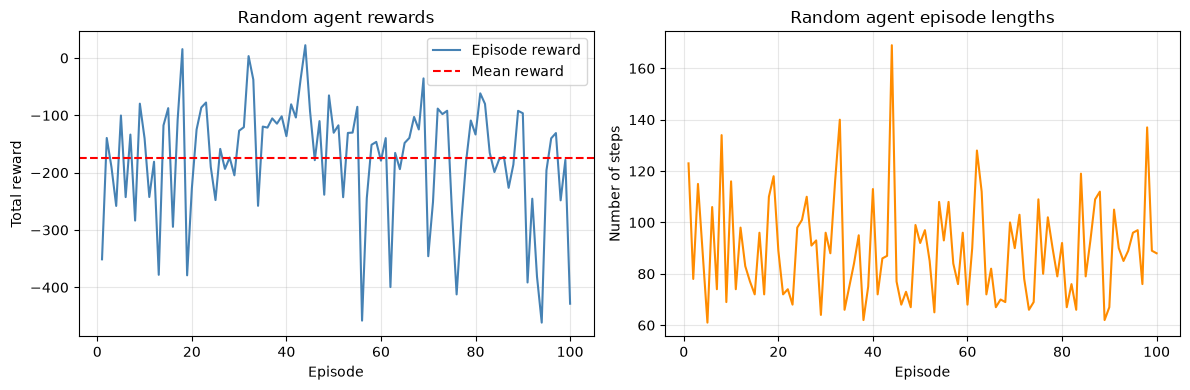

In [12]:
episodes = np.arange(1, AGENT_EPISODES + 1)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4),
)

axes[0].plot(
    episodes,
    baseline_rewards,
    color="steelblue",
    label="Episode reward",
)

axes[0].axhline(
    baseline_rewards.mean(),
    color="red",
    linestyle="--",
    label="Mean reward",
)

axes[0].set_title("Random agent rewards")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Total reward")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    episodes,
    baseline_lengths,
    color="darkorange",
)

axes[1].set_title("Random agent episode lengths")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Number of steps")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### State and Action Spaces

Before building the model, we must understand what the agent sees and what it can do.

- **State space:** 8 values describe position, velocity, angle, angular velocity, and leg contacts.
- **Action space:** 4 discrete choices: do nothing, fire the left engine, fire the main engine, or fire the right engine.

The code reads these dimensions to build the neural networks: 8 inputs for the state and 4 outputs for the actions. The states are converted to tensors later; this notebook does not normalize the observations.

In [13]:
state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size) 
print("Action size:", action_size)

State size: 8
Action size: 4


### Actor-Critic Architecture

We use an **Actor-Critic** design with two separate neural networks:

1. **The Actor**: Predicts the probability of each action. It tells the agent *what to do*.
2. **The Critic**: Estimates the value of the current state. It tells the agent *how good* the current situation is.

The Actor first produces one logit for every action. PyTorch converts the logits into probabilities:

$$\pi(a \mid s) = \operatorname{softmax}(\text{logits}(s))_a$$

Here, $s$ is the current state, $a$ is one action, and $\pi(a \mid s)$ is the probability of choosing that action. The Critic produces one number, $V(s)$, which estimates the future reward from state $s$.

By combining both, the agent can learn a policy while also understanding the value of the states it visits.

In [14]:
class ActorCritic(nn.Module):
    def __init__(self, state_size, action_size, hidden_size=64):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, action_size),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self,state):
        action_logits = self.actor(state)
        state_value = self.critic(state).squeeze(-1)  # Remove the last dimension
        return action_logits, state_value

    def get_action_and_value(
        self, state, action=None
    ):
        action_logits, state_value = self(state)

        distribution = Categorical(logits=action_logits)

        if action is None:
            action = distribution.sample()
        log_probability = distribution.log_prob(action)
        entropy = distribution.entropy()

        return (
            action, log_probability, entropy, state_value)
    

In [15]:
device = torch.device("cpu")

set_seed(SEED)

model = ActorCritic(
    state_size=state_size,
    action_size=action_size,
    hidden_size=64,
).to(device)

print(model)

ActorCritic(
  (actor): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


### Model Verification

Before training, we convert one state to a tensor and pass it through the model. We print the sampled action, its log-probability, the policy entropy, and the Critic value. This checks that the model returns every value needed by PPO.

**Expected result:** one valid action from 0 to 3 and finite numerical outputs.

In [16]:
state, info = env.reset(seed=SEED)

state_tensor = torch.as_tensor(  #transforme le state en tensor pour le model
    state, 
    dtype = torch.float32,
    device=device
).unsqueeze(0)  # Add batch dimension


print("original state:", state.shape)
print("state tensor:", state_tensor.shape)



original state: (8,)
state tensor: torch.Size([1, 8])


In [17]:
with torch.no_grad():
    action, log_prob, entropy, state_value = (
        model.get_action_and_value(state_tensor)
    )

print("Action:", action.item())
print("Log probability:", log_prob.item())
print("Entropy:", entropy.item())
print("State value:", state_value.item())

Action: 0
Log probability: -1.4023222923278809
Entropy: 1.3858437538146973
State value: 0.14401423931121826


In [18]:
next_state, reward, terminated, truncated, info = env.step(action.item())

print("Next state:", next_state)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)

Next state: [ 0.00459394  1.424763    0.23233266  0.29476273 -0.00525882 -0.05208294
  0.          0.        ]
Reward: 1.1449811454510836
Terminated: False
Truncated: False


### Experience Storage

PPO is an **on-policy** algorithm, meaning it learns from data collected by the current version of the agent. We use a buffer to store:
- **States**: What the agent saw.
- **Actions**: What the agent did.
- **Log-probabilities**: The logarithm of the probability of each selected action.
- **Rewards**: The immediate feedback from the environment.
- **Next states**: What the agent sees after each action.
- **Values and end flags**: The Critic estimate and information about episode completion.

Once the buffer is full, we use this data to update the network and then clear the buffer for the next set of experiences.

In [19]:
class RolloutStorage:
    def __init__(self):
        self.clear()

    def clear(self):
        self.states = []
        self.actions = []
        self.rewards = []
        self.next_states = []
        self.terminated = []
        self.truncated = []
        self.log_probs = []
        self.values = []

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        terminated,
        truncated,
        log_prob,
        value
    ):
        self.states.append(state.copy())
        self.actions.append(action)
        self.rewards.append(reward)
        self.next_states.append(next_state.copy())
        self.terminated.append(terminated)
        self.truncated.append(truncated)
        self.log_probs.append(log_prob)
        self.values.append(value)
    def __len__(self):
        return len(self.rewards)


In [20]:
storage = RolloutStorage()

storage.add(
    state=state,
    action=action.item(),
    reward=reward,
    next_state=next_state,
    terminated=terminated,
    truncated=truncated,
    log_prob=log_prob.item(),
    value=state_value.item(),
)

assert len(storage) == 1
assert storage.states[0].shape == (state_size,)
assert storage.next_states[0].shape == (state_size,)
assert 0 <= storage.actions[0] < action_size

print("Transition stored correctly")

Transition stored correctly


### The Rollout Phase

In a **rollout**, the agent interacts with the environment for a fixed number of steps. It follows its current policy and stores every transition. The Actor later learns which actions worked well, while the Critic learns to estimate returns.

**Expected result:** the storage contains exactly the requested number of transitions, even when several episodes finish inside one rollout.

In [21]:
def state_to_tensor(state):
    return torch.tensor(
        state,
        dtype=torch.float32,
    ).unsqueeze(0)

def collect_rollout(
    env,
    model,
    storage,
    state,
    episode_reward,
    steps=256,
):
    storage.clear()
    finished_rewards = []

    for _ in range(steps):
        state_tensor = state_to_tensor(state)

        with torch.no_grad():
            action, log_prob, entropy, value = (
                model.get_action_and_value(state_tensor)
            )

        next_state, reward, terminated, truncated, info = (
            env.step(action.item())
        )

        storage.add(
            state,
            action.item(),
            reward,
            next_state,
            terminated,
            truncated,
            log_prob.item(),
            value.item(),
        )

        episode_reward += reward
        state = next_state

        if terminated or truncated:
            finished_rewards.append(episode_reward)
            episode_reward = 0
            state, info = env.reset()

    return state, episode_reward, finished_rewards


In [22]:
storage = RolloutStorage()

state, info = env.reset(seed=SEED)
episode_reward = 0

state, episode_reward, episode_rewards = collect_rollout(
    env,
    model,
    storage,
    state,
    episode_reward,
    steps=256,
)

print("Collected steps:", len(storage))
print("Finished episodes:", len(episode_rewards))
print("Episode rewards:", episode_rewards)

Collected steps: 256
Finished episodes: 2
Episode rewards: [np.float64(-115.83021066308171), np.float64(-150.10467886751974)]


### Mini-batch Training

PPO does not update the model with the complete rollout in one large step. It shuffles the transitions and divides them into **mini-batches**. Each mini-batch produces a smaller gradient update. Repeating this process for several epochs uses the collected experience efficiently while keeping updates controlled.

The small example above collects 256 transitions. The main training loop later collects 1024 transitions and uses mini-batches of 64.

In [23]:
states = torch.tensor(
    np.array(storage.states)
)

actions = torch.tensor(storage.actions)
rewards = torch.tensor(storage.rewards)

next_states = torch.tensor(
    np.array(storage.next_states)
)

terminated = torch.tensor(storage.terminated)
truncated = torch.tensor(storage.truncated)
old_log_probs = torch.tensor(storage.log_probs)
values = torch.tensor(storage.values)

print(states.dtype)
print(actions.dtype)
print(rewards.dtype)
print(terminated.dtype)

torch.float32
torch.int64
torch.float64
torch.bool


### Generalized Advantage Estimation (GAE)

The **advantage** tells us whether an action produced a better result than the Critic expected. PPO uses this signal to increase or decrease the probability of that action.

First, we compute the temporal-difference error:

$$\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$$

Then we work backward through the rollout:

$$A_t = \delta_t + \gamma \lambda A_{t+1}$$

Here, $t$ is the current step, $r_t$ is its reward, $V(s_t)$ is the Critic estimate, $\delta_t$ is the one-step error, and $A_t$ is the advantage. The discount factor $\gamma = 0.99$ controls the importance of future rewards. The parameter $\lambda = 0.95$ controls how much future errors influence the current advantage. At an episode boundary, the code stops carrying GAE into the next episode.

**Expected result:** one advantage and one target return for every stored transition.

In [24]:
def compute_gae(
    model,
    rewards,
    values,
    next_states,
    terminated,
    truncated,
    gamma=0.99,
    gae_lambda=0.95,
):
    with torch.no_grad():
        _, next_values = model(next_states)

    advantages = torch.zeros_like(rewards)
    gae = 0.0

    for t in reversed(range(len(rewards))):
        bootstrap_mask = 1.0 - terminated[t].float()

        continue_mask = 1.0 - (
            terminated[t] | truncated[t]
        ).float()

        delta = (
            rewards[t]
            + gamma * bootstrap_mask * next_values[t]
            - values[t]
        )

        gae = (
            delta
            + gamma
            * gae_lambda
            * continue_mask
            * gae
        )

        advantages[t] = gae

    returns = advantages + values

    return advantages, returns

In [25]:
advantages, returns = compute_gae(
    model=model,
    rewards=rewards,
    values=values,
    next_states=next_states,
    terminated=terminated,
    truncated=truncated,
)

In [26]:
print("Advantages:", advantages.shape)
print("Returns:", returns.shape)

print("First advantages:", advantages[:5])
print("First returns:", returns[:5])

Advantages: torch.Size([256])
Returns: torch.Size([256])
First advantages: tensor([ -4.6192,  -7.1240,  -9.1390, -11.2604,  -6.6869], dtype=torch.float64)
First returns: tensor([ -4.4752,  -6.9781,  -8.9930, -11.1144,  -6.5414], dtype=torch.float64)


### Proximal Policy Optimization (PPO)

PPO improves the policy but prevents one update from changing it too much. It compares the probability of the stored action under the new and old policies:

$$r_t(\theta) = \frac{\pi_{\theta}(a_t \mid s_t)}{\pi_{\theta_{\text{old}}}(a_t \mid s_t)}$$

The policy loss uses a clipped ratio:

$$L_{\text{policy}} = -\mathbb{E}\left[\min\left(r_t A_t,\; \operatorname{clip}(r_t, 1-\epsilon, 1+\epsilon) A_t\right)\right]$$

Here, $s_t$ and $a_t$ are the stored state and action, $\pi_{\theta}$ is the new policy, $\pi_{\theta_{\text{old}}}$ is the policy that collected the rollout, and $A_t$ is the advantage. We use $\epsilon = 0.2$, so the ratio is clipped to the interval from 0.8 to 1.2. This limits the effect of a very large policy update.

In [27]:
set_seed(SEED)

model = ActorCritic(
    state_size=state_size,
    action_size=action_size,
    hidden_size=64,
).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
)

print("Fresh untrained model created")

Fresh untrained model created


### The Training Loop

Training repeats the same cycle: collect a rollout, compute advantages and returns, shuffle the data, and update the model with mini-batches. This notebook uses 2000 updates, 1024 rollout steps, 4 PPO epochs, and mini-batches of 64.

The optimized loss is:

$$L_{\text{total}} = L_{\text{policy}} + 0.5L_{\text{value}} - 0.001H(\pi)$$

$L_{\text{policy}}$ is the clipped PPO loss. $L_{\text{value}}$ is the Smooth L1 error between the Critic prediction and the target return. $H(\pi)$ is policy entropy, which rewards exploration. The minus sign means that higher entropy reduces the total loss. Gradient clipping also prevents extremely large parameter updates.

**Expected result:** training rewards generally rise, while the best evaluated checkpoint is kept even if later updates become worse.

In [28]:
TRAINING_UPDATES = 2000
ROLLOUT_STEPS = 1024

PPO_EPOCHS = 4
MINIBATCH_SIZE = 64
EVAL_INTERVAL = 50
EVAL_EPISODES = 100
ENTROPY_COEF = 0.001
BEST_MODEL_PATH = PPO_DIR / "ppo_lunar_lander_stable_best.pt"

def evaluate_during_training(
    eval_env,
    model,
    episodes,
    base_seed,
):
    rewards = []

    with torch.random.fork_rng():
        torch.manual_seed(base_seed)

        for episode in range(episodes):
            state, info = eval_env.reset(
                seed=base_seed + episode
            )
            total_reward = 0
            finished = False

            while not finished:
                state_tensor = state_to_tensor(state)

                with torch.no_grad():
                    action_logits, _ = model(state_tensor)
                    action = torch.argmax(
                        action_logits,
                        dim=-1,
                    )

                state, reward, terminated, truncated, info = (
                    eval_env.step(action.item())
                )

                total_reward += reward
                finished = terminated or truncated

            rewards.append(total_reward)

    return np.mean(rewards)

all_rewards = []
storage = RolloutStorage()
state, info = env.reset(seed=SEED)
episode_reward = 0

eval_env = make_env(seed=SEED + 10000)
best_mean_reward = evaluate_during_training(
    eval_env=eval_env,
    model=model,
    episodes=EVAL_EPISODES,
    base_seed=SEED + 10000,
)

torch.save(
    model.state_dict(),
    BEST_MODEL_PATH,
)

print(
    f"Initial evaluation: {best_mean_reward:.2f}"
)

for update in range(TRAINING_UPDATES):
    # Collect a fresh rollout with the current policy.
    state, episode_reward, episode_rewards = collect_rollout(
        env,
        model,
        storage,
        state,
        episode_reward,
        steps=ROLLOUT_STEPS,
    )

    all_rewards.extend(episode_rewards)

    # Convert the stored rollout to tensors for PyTorch.
    states = torch.tensor(
        np.array(storage.states)
    )

    actions = torch.tensor(storage.actions)
    rewards = torch.tensor(storage.rewards)

    next_states = torch.tensor(
        np.array(storage.next_states)
    )

    terminated = torch.tensor(storage.terminated)
    truncated = torch.tensor(storage.truncated)
    old_log_probs = torch.tensor(storage.log_probs)
    values = torch.tensor(storage.values)

    # Compute advantages and target returns.
    advantages, returns = compute_gae(
        model=model,
        rewards=rewards,
        values=values,
        next_states=next_states,
        terminated=terminated,
        truncated=truncated,
    )

    advantages = (
        advantages - advantages.mean()
    ) / (
        advantages.std() + 1e-8
    )

    # Shuffle the rollout and split it into mini-batches.
    batch_size = len(states)
    batch_losses = []

    for epoch in range(PPO_EPOCHS):
        shuffled_indices = torch.randperm(batch_size)

        for start in range(0, batch_size, MINIBATCH_SIZE):
            batch_indices = shuffled_indices[
                start:start + MINIBATCH_SIZE
            ]

            _, new_log_probs, entropy, new_values = (
                model.get_action_and_value(
                    states[batch_indices],
                    actions[batch_indices],
                )
            )

            ratio = torch.exp(
                new_log_probs
                - old_log_probs[batch_indices]
            )

            clipped_ratio = torch.clamp(
                ratio,
                0.8,
                1.2,
            )

            batch_advantages = advantages[batch_indices]

            policy_loss = -torch.min(
                ratio * batch_advantages,
                clipped_ratio * batch_advantages,
            ).mean()

            value_loss = torch.nn.functional.smooth_l1_loss(
                new_values,
                returns[batch_indices],
            )

            loss = (
                policy_loss
                + 0.5 * value_loss
                - ENTROPY_COEF * entropy.mean()
            )

            if not torch.isfinite(loss):
                raise ValueError("Loss is not finite")

            optimizer.zero_grad()
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                0.5,
            )

            optimizer.step()
            batch_losses.append(loss.item())

    mean_loss = np.mean(batch_losses)

    if (update + 1) % 10 == 0:
        recent_rewards = all_rewards[-20:]

        if recent_rewards:
            mean_reward = np.mean(recent_rewards)
        else:
            mean_reward = 0

        print(
            f"Update {update + 1}, "
            f"mean reward: {mean_reward:.2f}, "
            f"loss: {mean_loss:.2f}"
        )

    if (update + 1) % EVAL_INTERVAL == 0:
        evaluation_mean = evaluate_during_training(
            eval_env=eval_env,
            model=model,
            episodes=EVAL_EPISODES,
            base_seed=SEED + 10000,
        )

        if not np.isfinite(evaluation_mean):
            raise ValueError("Evaluation reward is not finite")

        if evaluation_mean > best_mean_reward:
            best_mean_reward = evaluation_mean
            torch.save(
                model.state_dict(),
                BEST_MODEL_PATH,
            )
            saved_text = "saved"
        else:
            saved_text = "not saved"

        print(
            f"Evaluation: {evaluation_mean:.2f}, "
            f"best: {best_mean_reward:.2f}, "
            f"{saved_text}"
        )

model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device,
        weights_only=True,
    )
)

eval_env.close()

print("Best model loaded after training")

Initial evaluation: -501.69
Update 10, mean reward: -132.87, loss: 12.44
Update 20, mean reward: -147.63, loss: 10.92
Update 30, mean reward: -231.61, loss: 8.14
Update 40, mean reward: -113.09, loss: 9.51
Update 50, mean reward: -128.23, loss: 6.23
Evaluation: -885.04, best: -501.69, not saved
Update 60, mean reward: -187.46, loss: 7.94
Update 70, mean reward: -87.27, loss: 6.89
Update 80, mean reward: -41.24, loss: 7.45
Update 90, mean reward: -55.48, loss: 6.37
Update 100, mean reward: -74.25, loss: 3.45
Evaluation: -614.44, best: -501.69, not saved
Update 110, mean reward: -61.55, loss: 3.67
Update 120, mean reward: -26.77, loss: 2.87
Update 130, mean reward: -28.79, loss: 3.42
Update 140, mean reward: -25.37, loss: 4.09
Update 150, mean reward: 1.63, loss: 2.71
Evaluation: -909.86, best: -501.69, not saved
Update 160, mean reward: 15.13, loss: 2.35
Update 170, mean reward: 6.31, loss: 1.72
Update 180, mean reward: -11.60, loss: 1.00
Update 190, mean reward: 0.53, loss: 2.06
Update

### Training Progress

This graph plots the total reward of every completed episode. The red dashed line is zero reward. Individual rewards remain noisy, so the important pattern is the general movement from large negative rewards toward positive rewards.

**Expected result:** later episodes usually receive higher rewards than the random baseline, although some difficult episodes can still be poor.

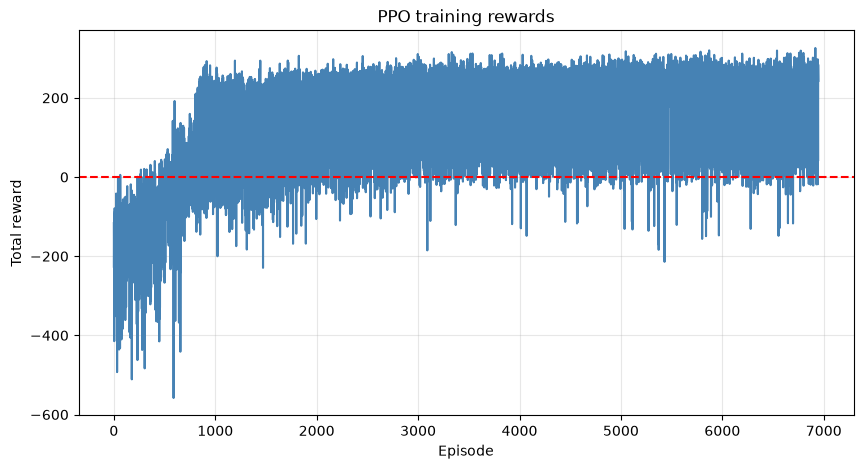

In [29]:
plt.figure(figsize=(10, 5))

plt.plot(
    all_rewards,
    color="steelblue",
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
)

plt.title("PPO training rewards")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.grid(alpha=0.3)

plt.show()

### Evaluation

Evaluation runs complete episodes without updating the model. Instead of sampling an action, the agent always selects the action with the largest logit. Using the same episode seeds makes model comparisons more stable.

We inspect the mean, standard deviation, minimum, maximum, and the number of episodes with reward at least 200. A high mean is useful, but the minimum and standard deviation show whether failures still happen.

In [30]:
def evaluate_agent(env, model, episodes=20):
    rewards = []

    for episode in range(episodes):
        state, info = env.reset(seed=SEED + episode)
        total_reward = 0
        finished = False

        while not finished:
            state_tensor = state_to_tensor(state)

            with torch.no_grad():
                action_logits, state_value = model(state_tensor)
                action = torch.argmax(
                    action_logits,
                    dim=-1,
                ).item()

            state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward
            finished = terminated or truncated

        rewards.append(total_reward)

    return np.array(rewards)

In [31]:
evaluation_rewards = evaluate_agent(
    env,
    model,
    episodes=20,
)

print("Mean reward:", evaluation_rewards.mean())
print("Minimum reward:", evaluation_rewards.min())
print("Maximum reward:", evaluation_rewards.max())

Mean reward: 230.37350974353208
Minimum reward: -17.252468171304827
Maximum reward: 293.14056350016506


### Saving the Model

During training, the notebook evaluates the policy every 50 updates. It saves a checkpoint only when the evaluation mean improves. After training, it loads the best saved checkpoint instead of keeping the final, possibly weaker, update.

The main checkpoint is `PPO/ppo_lunar_lander_stable_best.pt`. Saving the weights lets us evaluate or fine-tune the policy without repeating the complete training run.

In [32]:
print("Best model path:", BEST_MODEL_PATH)
print("The best evaluated model is loaded")

Best model path: PPO/ppo_lunar_lander_stable_best.pt
The best evaluated model is loaded


In [33]:
evaluation_rewards = evaluate_agent(
    env,
    model,
    episodes=100,
)

print("Mean reward:", evaluation_rewards.mean())
print("Standard deviation:", evaluation_rewards.std())
print("Minimum reward:", evaluation_rewards.min())
print("Maximum reward:", evaluation_rewards.max())
print(
    "Episodes above 200:",
    np.sum(evaluation_rewards >= 200),
)

Mean reward: 223.0426061954795
Standard deviation: 74.25216071115946
Minimum reward: -147.75786667385603
Maximum reward: 296.664211729257
Episodes above 200: 82


### Fine-tuning

Fine-tuning starts from `PPO/ppo_lunar_lander_stable_best.pt` instead of random weights. It uses 500 additional updates and a smaller learning rate of `0.00003`, so the policy changes more carefully.

The result is saved separately as `PPO/ppo_lunar_lander_stable_finetuned_best.pt`. The original strong checkpoint is not overwritten.

In [34]:
def fine_tune_ppo(
    env,
    model,
    source_path,
    target_path,
    updates=500,
    learning_rate=0.00003,
    rollout_steps=1024,
    eval_interval=50,
    eval_episodes=100,
):
    # Load the strong model and create a fresh optimizer.
    model.load_state_dict(
        torch.load(
            source_path,
            map_location=device,
            weights_only=True,
        )
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    storage = RolloutStorage()
    fine_tune_rewards = []
    state, info = env.reset(seed=SEED + 20000)
    episode_reward = 0

    eval_env = make_env(seed=SEED + 20000)
    best_mean_reward = evaluate_during_training(
        eval_env=eval_env,
        model=model,
        episodes=eval_episodes,
        base_seed=SEED + 20000,
    )

    # Save the starting model to a new file.
    torch.save(model.state_dict(), target_path)
    print(f"Initial fine-tune evaluation: {best_mean_reward:.2f}")

    for update in range(updates):
        state, episode_reward, episode_rewards = collect_rollout(
            env,
            model,
            storage,
            state,
            episode_reward,
            steps=rollout_steps,
        )

        fine_tune_rewards.extend(episode_rewards)

        states = torch.tensor(np.array(storage.states))
        actions = torch.tensor(storage.actions)
        rewards = torch.tensor(storage.rewards)
        next_states = torch.tensor(np.array(storage.next_states))
        terminated = torch.tensor(storage.terminated)
        truncated = torch.tensor(storage.truncated)
        old_log_probs = torch.tensor(storage.log_probs)
        values = torch.tensor(storage.values)

        advantages, returns = compute_gae(
            model=model,
            rewards=rewards,
            values=values,
            next_states=next_states,
            terminated=terminated,
            truncated=truncated,
        )

        advantages = (
            advantages - advantages.mean()
        ) / (advantages.std() + 1e-8)

        batch_size = len(states)
        batch_losses = []

        for epoch in range(PPO_EPOCHS):
            shuffled_indices = torch.randperm(batch_size)

            for start in range(0, batch_size, MINIBATCH_SIZE):
                batch_indices = shuffled_indices[
                    start:start + MINIBATCH_SIZE
                ]

                _, new_log_probs, entropy, new_values = (
                    model.get_action_and_value(
                        states[batch_indices],
                        actions[batch_indices],
                    )
                )

                ratio = torch.exp(
                    new_log_probs
                    - old_log_probs[batch_indices]
                )
                clipped_ratio = torch.clamp(ratio, 0.8, 1.2)
                batch_advantages = advantages[batch_indices]

                policy_loss = -torch.min(
                    ratio * batch_advantages,
                    clipped_ratio * batch_advantages,
                ).mean()

                value_loss = torch.nn.functional.smooth_l1_loss(
                    new_values,
                    returns[batch_indices],
                )

                loss = (
                    policy_loss
                    + 0.5 * value_loss
                    - ENTROPY_COEF * entropy.mean()
                )

                if not torch.isfinite(loss):
                    raise ValueError("Fine-tune loss is not finite")

                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    0.5,
                )
                optimizer.step()
                batch_losses.append(loss.item())

        mean_loss = np.mean(batch_losses)

        if (update + 1) % 10 == 0:
            recent_rewards = fine_tune_rewards[-20:]
            mean_reward = (
                np.mean(recent_rewards)
                if recent_rewards
                else 0
            )
            print(
                f"Fine-tune {update + 1}, "
                f"mean reward: {mean_reward:.2f}, "
                f"loss: {mean_loss:.2f}"
            )

        if (update + 1) % eval_interval == 0:
            evaluation_mean = evaluate_during_training(
                eval_env=eval_env,
                model=model,
                episodes=eval_episodes,
                base_seed=SEED + 20000,
            )

            if evaluation_mean > best_mean_reward:
                best_mean_reward = evaluation_mean
                torch.save(model.state_dict(), target_path)
                saved_text = "saved"
            else:
                saved_text = "not saved"

            print(
                f"Fine-tune evaluation: {evaluation_mean:.2f}, "
                f"best: {best_mean_reward:.2f}, "
                f"{saved_text}"
            )

    model.load_state_dict(
        torch.load(
            target_path,
            map_location=device,
            weights_only=True,
        )
    )
    eval_env.close()

    return fine_tune_rewards, best_mean_reward


FINE_TUNE_SOURCE_PATH = PPO_DIR / "ppo_lunar_lander_stable_best.pt"
FINE_TUNE_MODEL_PATH = PPO_DIR / "ppo_lunar_lander_stable_finetuned_best.pt"

fine_tune_rewards, fine_tune_best_reward = fine_tune_ppo(
    env=env,
    model=model,
    source_path=FINE_TUNE_SOURCE_PATH,
    target_path=FINE_TUNE_MODEL_PATH,
)

print("Fine-tuned model:", FINE_TUNE_MODEL_PATH)
print("Best fine-tune reward:", fine_tune_best_reward)

Initial fine-tune evaluation: 213.63
Fine-tune 10, mean reward: 200.96, loss: 3.78
Fine-tune 20, mean reward: 205.06, loss: 5.08
Fine-tune 30, mean reward: 210.17, loss: 2.95
Fine-tune 40, mean reward: 224.76, loss: 3.65
Fine-tune 50, mean reward: 218.15, loss: 4.17
Fine-tune evaluation: 204.24, best: 213.63, not saved
Fine-tune 60, mean reward: 225.24, loss: 2.25
Fine-tune 70, mean reward: 206.11, loss: 3.04
Fine-tune 80, mean reward: 201.46, loss: 2.21
Fine-tune 90, mean reward: 207.80, loss: 4.60
Fine-tune 100, mean reward: 232.09, loss: 3.53
Fine-tune evaluation: 213.90, best: 213.90, saved
Fine-tune 110, mean reward: 231.64, loss: 1.91
Fine-tune 120, mean reward: 209.73, loss: 3.32
Fine-tune 130, mean reward: 220.92, loss: 4.61
Fine-tune 140, mean reward: 217.58, loss: 4.55
Fine-tune 150, mean reward: 217.44, loss: 3.64
Fine-tune evaluation: 214.64, best: 214.64, saved
Fine-tune 160, mean reward: 221.16, loss: 3.92
Fine-tune 170, mean reward: 220.33, loss: 3.66
Fine-tune 180, mean

### Fine-tuning Results

The first graph shows rewards collected during fine-tuning and a moving average over 20 episodes. The second graph evaluates both saved models on the same 100 seeds. Comparing the complete distributions is more useful than looking only at one mean value.

In this run, the mean changed only slightly, but the minimum reward improved strongly. This means fine-tuning mainly reduced the worst failure rather than producing a large increase in average reward.

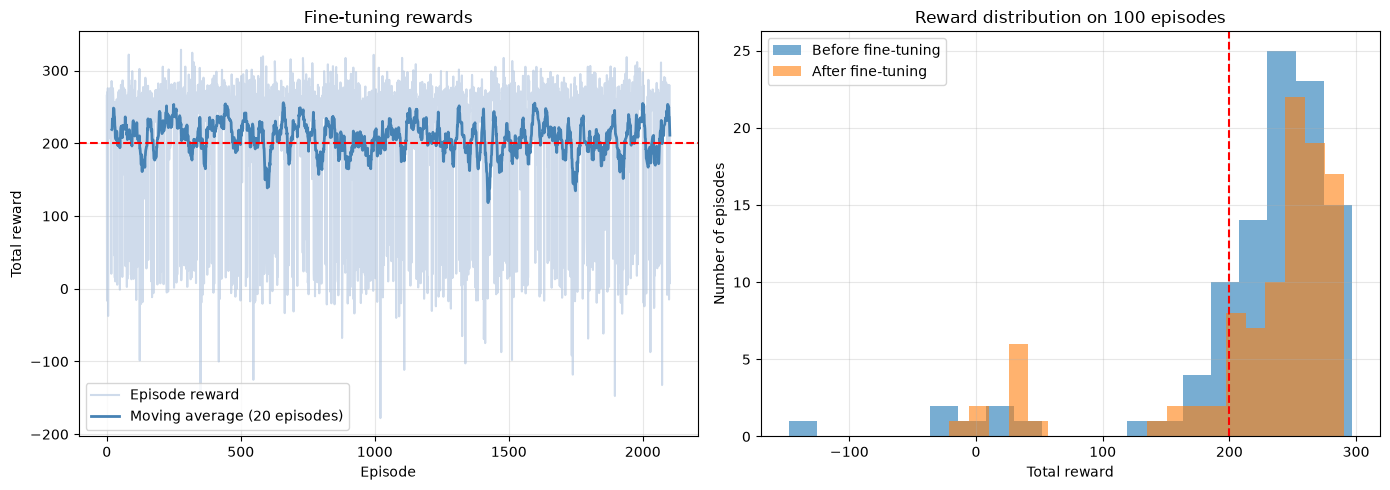

Before fine-tuning mean: 223.0426061954795
After fine-tuning mean: 223.92122838834973
Before fine-tuning minimum: -147.75786667385603
After fine-tuning minimum: -20.973788251878773


In [35]:
if "fine_tune_rewards" not in globals():
    raise NameError(
        "Run the fine-tuning cell before creating the graphs"
    )


def evaluate_saved_model(path, episodes=100):
    comparison_model = ActorCritic(
        state_size=state_size,
        action_size=action_size,
        hidden_size=64,
    ).to(device)

    comparison_model.load_state_dict(
        torch.load(
            path,
            map_location=device,
            weights_only=True,
        )
    )

    rewards = []

    for episode in range(episodes):
        state, info = env.reset(seed=SEED + episode)
        total_reward = 0
        finished = False

        while not finished:
            state_tensor = state_to_tensor(state)

            with torch.no_grad():
                action_logits, state_value = comparison_model(
                    state_tensor
                )
                action = torch.argmax(
                    action_logits,
                    dim=-1,
                ).item()

            state, reward, terminated, truncated, info = (
                env.step(action)
            )
            total_reward += reward
            finished = terminated or truncated

        rewards.append(total_reward)

    return np.array(rewards)


stable_rewards = evaluate_saved_model(
    FINE_TUNE_SOURCE_PATH
)
fine_tuned_rewards = evaluate_saved_model(
    FINE_TUNE_MODEL_PATH
)

window = 20
moving_average = np.convolve(
    fine_tune_rewards,
    np.ones(window) / window,
    mode="valid",
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    fine_tune_rewards,
    color="lightsteelblue",
    alpha=0.6,
    label="Episode reward",
)
axes[0].plot(
    np.arange(window - 1, len(fine_tune_rewards)),
    moving_average,
    color="steelblue",
    linewidth=2,
    label="Moving average (20 episodes)",
)
axes[0].axhline(200, color="red", linestyle="--")
axes[0].set_title("Fine-tuning rewards")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Total reward")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].hist(
    stable_rewards,
    bins=20,
    alpha=0.6,
    label="Before fine-tuning",
)
axes[1].hist(
    fine_tuned_rewards,
    bins=20,
    alpha=0.6,
    label="After fine-tuning",
)
axes[1].axvline(200, color="red", linestyle="--")
axes[1].set_title("Reward distribution on 100 episodes")
axes[1].set_xlabel("Total reward")
axes[1].set_ylabel("Number of episodes")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Before fine-tuning mean:", stable_rewards.mean())
print("After fine-tuning mean:", fine_tuned_rewards.mean())
print("Before fine-tuning minimum:", stable_rewards.min())
print("After fine-tuning minimum:", fine_tuned_rewards.min())

### Conclusion

The random agent had a mean reward of about **-174.82**, so it usually failed to land safely. After PPO training, the stable model reached a mean reward of about **223.04** on 100 deterministic evaluation episodes, and 82 episodes scored at least 200.

Fine-tuning produced a smaller improvement in the mean, from about **223.04** to **223.92**, and increased the number of episodes scoring at least 200 from 82 to 83. The most important change was the minimum reward: it improved from about **-147.76** to **-20.97**. The standard deviation stayed almost unchanged, so we should not claim that all variation disappeared.

**What we learned:**
- The Actor selects actions and the Critic estimates state values.
- GAE creates a less noisy learning signal from rewards and Critic values.
- PPO clipping limits very large policy changes.
- Evaluation on many fixed seeds is more reliable than one successful episode.

The final checkpoint used for comparison is `PPO/ppo_lunar_lander_stable_finetuned_best.pt`.